# IF25-40305: Sistem Teknologi Multimedia (STM)
## Modul 11 — Deteksi Wajah, Landmark & Kode Digital: Haar vs CNN, 478 Titik Wajah, Kedipan, QR/Barcode & AR Sederhana

**Institut Teknologi Sumatera (ITERA) — Program Studi Informatika**
*Materi Kuliah & Hands-on Lab Semester Ganjil 2026/2027 · Pertemuan 11*

---

### 🎯 Capaian Pembelajaran Modul 11:
1. **Menemukan wajah** di foto dengan tiga generasi detektor: **Haar Cascade**, **HOG**, dan **CNN** (YuNet), lalu membandingkan hasil dan kecepatannya.
2. Mengambil **478 titik wajah** (*facial landmarks*) dengan **MediaPipe Face Landmarker**.
3. Menghitung **Eye Aspect Ratio (EAR)** untuk **mendeteksi kedipan** di video.
4. **Membaca barcode & QR code** dengan OpenCV, termasuk dari foto yang miring dan QR yang rusak sebagian.
5. **Menempel gambar** (kacamata, gambar di atas QR) = **AR sederhana**, memakai kanal alpha dan transformasi dari Pertemuan 7.
6. Menggabungkan semuanya di video, lalu menjalankan demo **filter wajah** dengan webcam.

### 🧭 Cara Memakai Notebook Ini
- Di kelas, dosen menjalankan bagian bertanda **🎬 Demo Dosen** di proyektor. Anda cukup memperhatikan dan menebak.
- Di rumah, jalankan notebook dari atas ke bawah. Sel bertanda **✏️ Coba Ubah** berisi angka yang boleh Anda ganti.
- Tidak ada challenge yang dinilai di notebook ini. Santai saja, dan banyak-banyak mencoba!
- Bagian 9 memakai script terpisah **`11_filter_wajah.py`** yang butuh webcam, jadi dijalankan di laptop Anda (bukan di Colab).

> 📎 Slide pendamping: *Pertemuan 11 — Deteksi Wajah, Landmark & Kode Digital* (mctm.web.id/stm). Angka di slide dihitung dari foto, video, dan kode yang sama dengan notebook ini.

## 1. Persiapan

Modul ini memakai **`opencv-contrib-python`**, **`mediapipe`**, **`numpy`**, dan **`matplotlib`**.

```bash
pip install opencv-contrib-python mediapipe numpy matplotlib
```

Dua paket **opsional** (notebook tetap jalan tanpa keduanya, bagian terkait dilewati):
- **`dlib-bin`** → detektor wajah **HOG** (Bagian 2.2). `pip install dlib-bin`
- **`scikit-image`** → gambar "peta arah tepi" HOG. `pip install scikit-image`

> ⚠️ **Haar cascade di OpenCV 5.** Mulai OpenCV 5, file Haar cascade tidak lagi ikut terpasang. Karena itu file
> `haarcascade_frontalface_default.xml` sudah disediakan di folder `model/`.

**Bahan yang dipakai** (semuanya domain publik atau CC0, rincian di `image/CREDITS.md` & `video/CREDITS.md`):
- `image/astronaut.png` — astronaut Eileen Collins (NASA);
- `image/kru_ekspedisi72.jpg`, `image/kru_sts131.jpg` — foto grup kru di Stasiun Luar Angkasa Internasional (NASA);
- `video/wawancara_kedip.mp4` — 20 detik wawancara Dr. Kelsey Young (NASA Goddard), dipotong & diperkecil;
- `image/qr_meja.jpg`, `image/barcode_produk.jpg`, `image/kacamata.png` — citra sintetis buatan pengampu;
- `model/face_landmarker.task` (MediaPipe, Apache-2.0), `model/face_detection_yunet_2023mar.onnx` (YuNet, MIT),
  `model/haarcascade_*.xml` (OpenCV, BSD).

In [1]:
import os
import time
import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image as PILImage
from IPython.display import Image, display
import mediapipe as mp
from mediapipe.tasks.python import vision, BaseOptions

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.grid'] = False
%config InlineBackend.figure_formats = ['jpeg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'pil_kwargs': {'quality': 85}}

os.makedirs("output", exist_ok=True)
print(f"OpenCV   : {cv2.__version__}")
print(f"MediaPipe: {mp.__version__}")
print(f"NumPy    : {np.__version__}")
try:
    import dlib
    print(f"dlib     : {dlib.__version__} ✅ (Bagian 2.2 aktif)")
except ImportError:
    dlib = None
    print("dlib     : tidak ada (opsional) — Bagian 2.2 dilewati. Pasang dengan: pip install dlib-bin")

OpenCV   : 5.0.0
MediaPipe: 1.2.3
NumPy    : 2.5.4
dlib     : 20.0.1 ✅ (Bagian 2.2 aktif)


In [2]:
# ---------- Fungsi bantu tampilan ----------
def cari_file(nama):
    # notebook bisa dijalankan dari root repo atau dari folder notebook_handson
    for p in [nama, f"notebook_handson/{nama}", f"../{nama}"]:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Berkas tidak ditemukan: {nama}")


def tampil(ax, img, judul=None):
    if img.ndim == 2:
        ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    else:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_xticks([]); ax.set_yticks([])
    if judul:
        ax.set_title(judul, fontsize=11, fontweight='bold')


def jajar(daftar, ukuran=4):
    # daftar = [(img, judul), ...] -> ditampilkan berdampingan
    fig, axes = plt.subplots(1, len(daftar), figsize=(ukuran * len(daftar), ukuran * 0.75))
    for ax, (im, judul) in zip(np.atleast_1d(axes), daftar):
        tampil(ax, im, judul)
    plt.tight_layout(); plt.show()


def tampil_gif(frames, nama, fps=24, lebar=360, langkah=2):
    # Simpan list frame (BGR) menjadi GIF animasi, lalu tampilkan di notebook
    tinggi = int(frames[0].shape[0] * lebar / frames[0].shape[1])
    gambar = [PILImage.fromarray(cv2.cvtColor(cv2.resize(f, (lebar, tinggi)), cv2.COLOR_BGR2RGB))
              for f in frames[::langkah]]
    path = os.path.join("output", nama)
    gambar[0].save(path, save_all=True, append_images=gambar[1:], duration=int(1000 * langkah / fps), loop=0)
    with open(path, "rb") as fh:
        display(Image(data=fh.read(), format="gif"))
    print(f"GIF disimpan: {path} ({os.path.getsize(path) / 1024:.0f} KB)")


def tulis(img, teks, xy, skala=0.7, warna=(255, 255, 255)):
    # teks dengan garis tepi hitam agar terbaca di latar apa pun
    cv2.putText(img, teks, xy, cv2.FONT_HERSHEY_SIMPLEX, skala, (0, 0, 0), 5, cv2.LINE_AA)
    cv2.putText(img, teks, xy, cv2.FONT_HERSHEY_SIMPLEX, skala, warna, 2, cv2.LINE_AA)


def kotak(img, b, warna=(46, 16, 200), tebal=3):
    # gambar kotak (x, y, lebar, tinggi)
    x, y, w, h = [int(round(v)) for v in b[:4]]
    cv2.rectangle(img, (x, y), (x + w, y + h), warna, tebal, cv2.LINE_AA)


ASTRO = cv2.imread(cari_file("image/astronaut.png"))
EXP72 = cv2.imread(cari_file("image/kru_ekspedisi72.jpg"))
STS = cv2.imread(cari_file("image/kru_sts131.jpg"))
print("astronaut:", ASTRO.shape, "| ekspedisi72:", EXP72.shape, "| sts131:", STS.shape)

astronaut: (512, 512, 3) | ekspedisi72: (1067, 1600, 3) | sts131: (1064, 1600, 3)


---
## 2. Di Mana Wajahnya? (Deteksi Wajah)

**Deteksi wajah** = menjawab *"ada wajah atau tidak, dan di mana?"* Hasilnya berupa **kotak** `(x, y, lebar, tinggi)`.
Deteksi **belum** tahu *siapa* orangnya — itu tugas **pengenalan wajah** (*face recognition*), topik lain.

Kita coba tiga generasi detektor:

| Generasi | Detektor | Ide singkat |
|---|---|---|
| 2001 | **Haar Cascade** | Cari pola **kotak terang-gelap** (mata lebih gelap dari pipi) |
| 2005 | **HOG** (dlib) | Cari pola **arah tepi** yang mirip bentuk wajah |
| 2015+ | **CNN** (YuNet, dlib-CNN) | Jaringan saraf yang **belajar sendiri** dari ribuan foto wajah |

### 2.1 Haar Cascade: Pola Terang-Gelap

Ide Haar: pada wajah tegak, **pita mata selalu lebih gelap** daripada **pita pipi** di bawahnya, dan **pangkal hidung
lebih terang** daripada dua mata di sampingnya. Haar cukup membandingkan **rata-rata kecerahan** dua kotak.

Sel di bawah menghitung rata-rata itu di wajah astronaut. Posisi mata diambil dari MediaPipe (Bagian 3) supaya kotaknya pas.

In [3]:
# Model Haar (file XML) disediakan di folder model/
HAAR = cv2.CascadeClassifier(cari_file("model/haarcascade_frontalface_default.xml"))
YUNET = cari_file("model/face_detection_yunet_2023mar.onnx")


def deteksi_haar(img, scale=1.1, tetangga=5, min_size=30):
    abu = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)          # Haar bekerja di citra abu-abu
    return [tuple(int(v) for v in b) for b in
            HAAR.detectMultiScale(abu, scaleFactor=scale, minNeighbors=tetangga, minSize=(min_size, min_size))]


def deteksi_yunet(img, ambang=0.7):
    det = cv2.FaceDetectorYN.create(YUNET, "", (img.shape[1], img.shape[0]), ambang)
    _, wajah = det.detect(img)
    return [] if wajah is None else [tuple(float(v) for v in w) for w in wajah]


# Kotak wajah astronaut (dari YuNet), lalu potong & perbesar
x, y, w, h = deteksi_yunet(ASTRO)[0][:4]
print(f"Kotak wajah astronaut: x={x:.0f}, y={y:.0f}, lebar={w:.0f}, tinggi={h:.0f}")

Kotak wajah astronaut: x=178, y=63, lebar=90, tinggi=113


[ WARN:0@0.420] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


In [4]:
# MediaPipe Face Landmarker (dibahas di Bagian 3) dipakai di sini hanya untuk tahu posisi mata
def buat_landmarker(mode="IMAGE", n=1):
    opsi = vision.FaceLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=cari_file("model/face_landmarker.task")),
        running_mode=getattr(vision.RunningMode, mode), num_faces=n, output_face_blendshapes=True)
    return vision.FaceLandmarker.create_from_options(opsi)


def ke_mp(img):
    # MediaPipe butuh gambar RGB dalam bungkus mp.Image
    return mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)))


def titik_wajah(hasil, w, h, i=0):
    # koordinat titik dalam MediaPipe berupa pecahan 0..1 -> ubah ke piksel
    return np.array([[p.x * w, p.y * h] for p in hasil.face_landmarks[i]], np.float32)


MATA_KANAN = [33, 160, 158, 133, 153, 144]   # mata kanan pemilik wajah (kiri di layar)
MATA_KIRI = [362, 385, 387, 263, 373, 380]   # mata kiri pemilik wajah (kanan di layar)


def pusat_mata(titik):
    return titik[MATA_KANAN].mean(axis=0), titik[MATA_KIRI].mean(axis=0)


LM_IMG = buat_landmarker("IMAGE")
hasil_astro = LM_IMG.detect(ke_mp(ASTRO))
TA = titik_wajah(hasil_astro, ASTRO.shape[1], ASTRO.shape[0])
mata_a, mata_b = pusat_mata(TA)
print("Pusat mata (layar kiri, layar kanan):", mata_a.round(), mata_b.round())

Pusat mata (layar kiri, layar kanan): [204. 101.] [247. 104.]


W0000 00:00:1794466302.872205 3973750 face_landmarker_graph.cc:181] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1794466302.879069 3973755 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794466302.890478 3973756 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Fitur 1 → pita mata: 148, pita pipi: 187, selisih: 39
Fitur 2 → mata: 138 | hidung: 191 | mata: 131


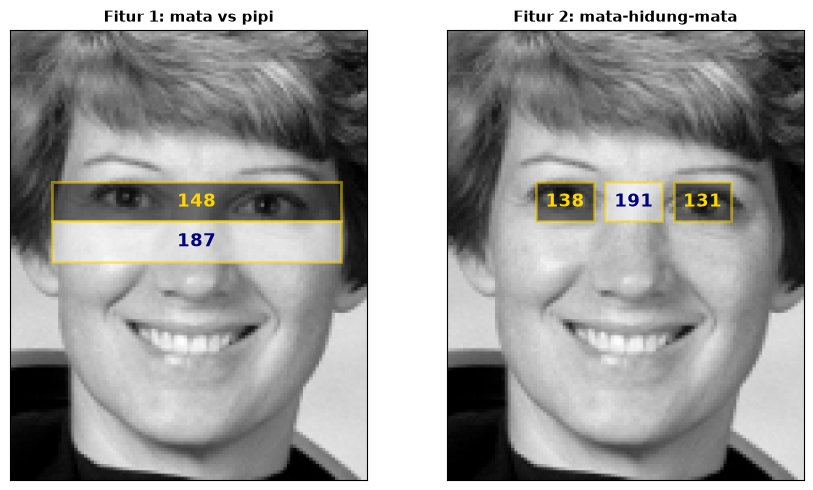

In [5]:
# Hitung dua fitur Haar di wajah astronaut
abu = cv2.cvtColor(ASTRO, cv2.COLOR_BGR2GRAY)
m = 0.12
x0, y0, x1, y1 = int(x - m * w), int(y - m * h), int(x + w * (1 + m)), int(y + h * (1 + m))
C = cv2.resize(abu[y0:y1, x0:x1], (400, int(400 * (y1 - y0) / (x1 - x0))), interpolation=cv2.INTER_AREA)
sx, sy = C.shape[1] / (x1 - x0), C.shape[0] / (y1 - y0)
mata_y = int(((mata_a[1] + mata_b[1]) / 2 - y0) * sy)
ax_, bx_ = int((mata_a[0] - x0) * sx), int((mata_b[0] - x0) * sx)
pita = int(0.09 * C.shape[0])

# Fitur 1: pita mata (gelap) vs pita pipi (terang) tepat di bawahnya
gelap = (int(ax_ - 0.55 * (bx_ - ax_)), mata_y - pita // 2, int(bx_ + 0.55 * (bx_ - ax_)), mata_y + pita // 2)
terang = (gelap[0], gelap[3], gelap[2], gelap[3] + pita)
rata = lambda r: C[r[1]:r[3], r[0]:r[2]].mean()
print(f"Fitur 1 → pita mata: {rata(gelap):.0f}, pita pipi: {rata(terang):.0f}, selisih: {rata(terang) - rata(gelap):.0f}")

# Fitur 2: mata kiri (gelap) - pangkal hidung (terang) - mata kanan (gelap)
lb = int(0.42 * (bx_ - ax_))
ki = (ax_ - lb // 2, mata_y - pita // 2, ax_ + lb // 2, mata_y + pita // 2)
te = ((ax_ + bx_) // 2 - lb // 2, mata_y - pita // 2, (ax_ + bx_) // 2 + lb // 2, mata_y + pita // 2)
ka = (bx_ - lb // 2, mata_y - pita // 2, bx_ + lb // 2, mata_y + pita // 2)
print(f"Fitur 2 → mata: {rata(ki):.0f} | hidung: {rata(te):.0f} | mata: {rata(ka):.0f}")

fig, axs = plt.subplots(1, 2, figsize=(9, 5))
for ax, judul, kotak_kotak in [(axs[0], "Fitur 1: mata vs pipi", [(gelap, "k"), (terang, "w")]),
                               (axs[1], "Fitur 2: mata-hidung-mata", [(ki, "k"), (te, "w"), (ka, "k")])]:
    tampil(ax, C, judul)
    for (a1, b1, a2, b2), warna in kotak_kotak:
        ax.add_patch(Rectangle((a1, b1), a2 - a1, b2 - b1, facecolor=warna, alpha=0.5, edgecolor="gold", lw=2))
        ax.text((a1 + a2) / 2, (b1 + b2) / 2, f"{C[b1:b2, a1:a2].mean():.0f}", ha="center", va="center",
                fontsize=13, fontweight="bold", color="gold" if warna == "k" else "navy")
plt.tight_layout(); plt.show()

Satu fitur saja terlalu lemah — dinding bergaris pun bisa punya pita gelap-terang. Karena itu Haar memakai **ribuan fitur**
yang disusun seperti **satpam berlapis (cascade)**: jendela yang gagal di lapis awal langsung dibuang, hanya jendela
yang lolos semua lapis yang disebut "wajah". Jendela ini **digeser** ke seluruh foto, dalam berbagai ukuran.

Dua parameter penting `detectMultiScale`:
- `scaleFactor` — seberapa besar lompatan ukuran jendela (1.1 = naik 10% tiap langkah). Kecil = teliti tapi lambat.
- `minNeighbors` — berapa kotak bertumpuk yang dibutuhkan sebelum dipercaya. Kecil = banyak **salah deteksi**, besar = banyak wajah **terlewat**.

### 🎬 Demo Dosen — Haar di Foto Kru Ekspedisi 72
**Tebak dulu:** foto ini berisi 11 orang. Berapa kotak yang akan ditemukan Haar? Adakah kotak yang **bukan** wajah?

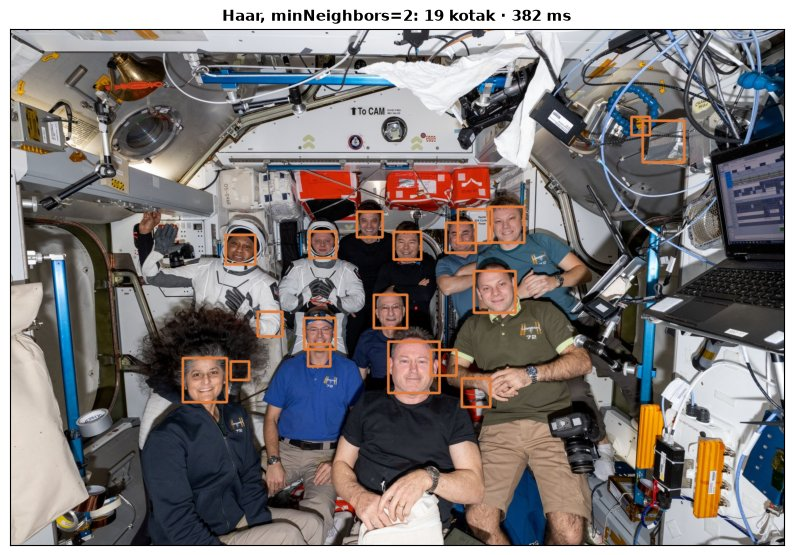

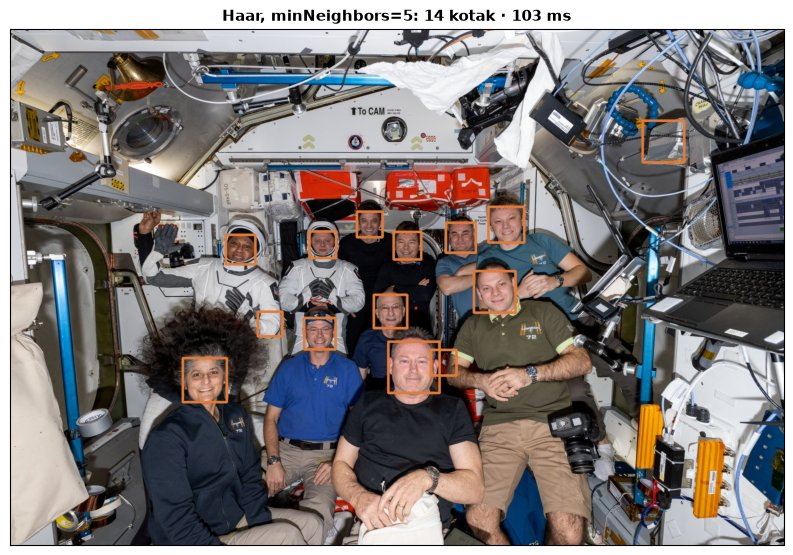

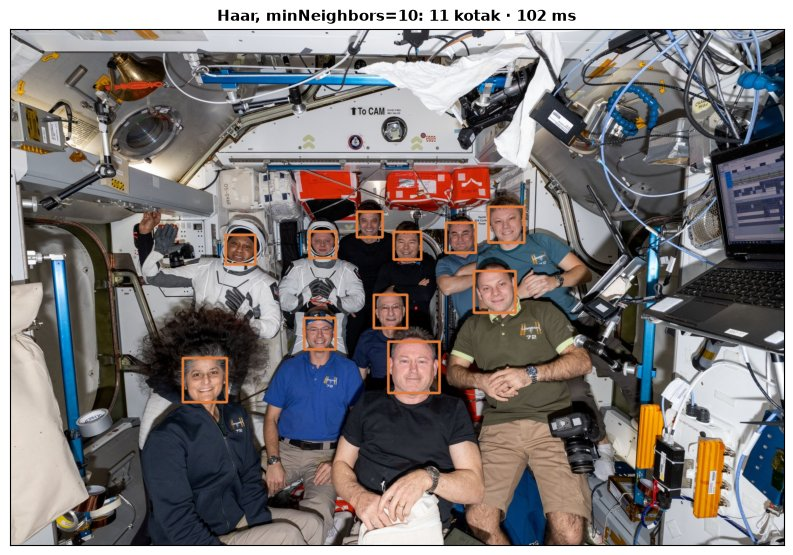

In [6]:
# ✏️ Coba Ubah: tetangga (minNeighbors) -> 1, 3, 5, 10
for tetangga in [2, 5, 10]:
    t = time.perf_counter()
    kotak_haar = deteksi_haar(EXP72, scale=1.1, tetangga=tetangga)
    dt = (time.perf_counter() - t) * 1000
    v = EXP72.copy()
    for b in kotak_haar:
        kotak(v, b, (57, 123, 224), 4)
    plt.figure(figsize=(10, 6.7)); tampil(plt.gca(), v, f"Haar, minNeighbors={tetangga}: {len(kotak_haar)} kotak · {dt:.0f} ms")
    plt.show()

### 2.2 HOG: Pola Arah Tepi (opsional, butuh `dlib-bin`)

Ingat Sobel di Pertemuan 9? HOG (*Histogram of Oriented Gradients*) membagi wajah menjadi petak-petak kecil, lalu mencatat
**ke arah mana tepi-tepinya**. Wajah punya "sidik arah tepi" yang khas: alis mendatar, sisi wajah tegak, dan seterusnya.
Karena memakai **arah**, bukan kecerahan, HOG lebih tahan terhadap perubahan cahaya daripada Haar.

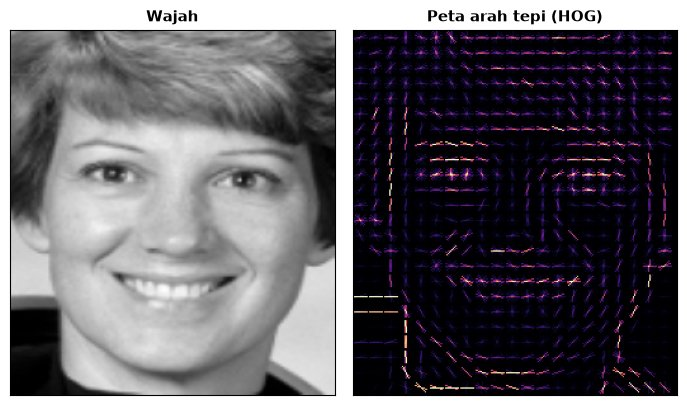

In [7]:
try:
    from skimage.feature import hog
    wajah = cv2.resize(abu[int(y - 0.15 * h):int(y + 1.1 * h), int(x - 0.1 * w):int(x + 1.1 * w)], (256, 288))
    _, peta = hog(wajah, orientations=9, pixels_per_cell=(12, 12), cells_per_block=(2, 2), visualize=True)
    fig, axs = plt.subplots(1, 2, figsize=(7, 4))
    tampil(axs[0], wajah, "Wajah")
    axs[1].imshow(np.clip(peta / peta.max() * 2.2, 0, 1), cmap="magma"); axs[1].set_xticks([]); axs[1].set_yticks([])
    axs[1].set_title("Peta arah tepi (HOG)", fontsize=11, fontweight="bold")
    plt.tight_layout(); plt.show()
except ImportError:
    print("scikit-image tidak terpasang — gambar peta HOG dilewati (pip install scikit-image).")

In [8]:
if dlib is not None:
    HOG = dlib.get_frontal_face_detector()

    def deteksi_hog(img, up=1):
        # dlib butuh RGB; up=1 artinya foto diperbesar 2x dulu agar wajah kecil ikut terlihat
        rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        return [(r.left(), r.top(), r.width(), r.height()) for r in HOG(rgb, up)]
else:
    deteksi_hog = None
    print("dlib tidak ada — HOG dilewati.")

### 2.3 CNN: Belajar dari Ribuan Contoh — YuNet

**YuNet** adalah CNN mungil (±230 KB, ±75 ribu parameter) yang dilatih dengan puluhan ribu foto wajah. Kita sudah memakainya
diam-diam di Pertemuan 10 (hidung badut)! Selain kotak, YuNet juga memberi **5 titik**: dua mata, ujung hidung, dua sudut bibir,
plus **skor keyakinan**.

Skor keyakinan YuNet: 0.932
5 titik (x, y):
 [[200. 102.]
 [247. 103.]
 [220. 125.]
 [199. 143.]
 [240. 144.]]


[ WARN:0@1.814] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


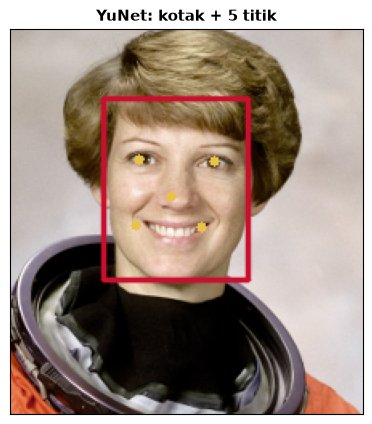

In [9]:
wajah_yunet = deteksi_yunet(ASTRO)
x_, y_, w_, h_ = wajah_yunet[0][:4]
lima = np.array(wajah_yunet[0][4:14]).reshape(5, 2)
skor = wajah_yunet[0][14]
v = ASTRO.copy()
kotak(v, (x_, y_, w_, h_), (46, 16, 200), 2)
for (px, py), nama in zip(lima, ["mata", "mata", "hidung", "bibir", "bibir"]):
    cv2.circle(v, (int(px), int(py)), 3, (74, 195, 232), -1)
print(f"Skor keyakinan YuNet: {skor:.3f}")
print("5 titik (x, y):\n", lima.round(0))
plt.figure(figsize=(5, 5)); tampil(plt.gca(), v[20:260, 120:340], "YuNet: kotak + 5 titik"); plt.show()

### 🎬 Demo Dosen — Adu Detektor
**Tebak dulu:** mana yang paling banyak menemukan wajah? Mana yang paling cepat? Mana yang membuat **salah deteksi**?

Ekspedisi72  Haar  : 14 wajah,    115 ms


Ekspedisi72  HOG   : 11 wajah,    463 ms
Ekspedisi72  YuNet : 11 wajah,     74 ms


[ WARN:0@2.474] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now
[ WARN:0@2.478] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


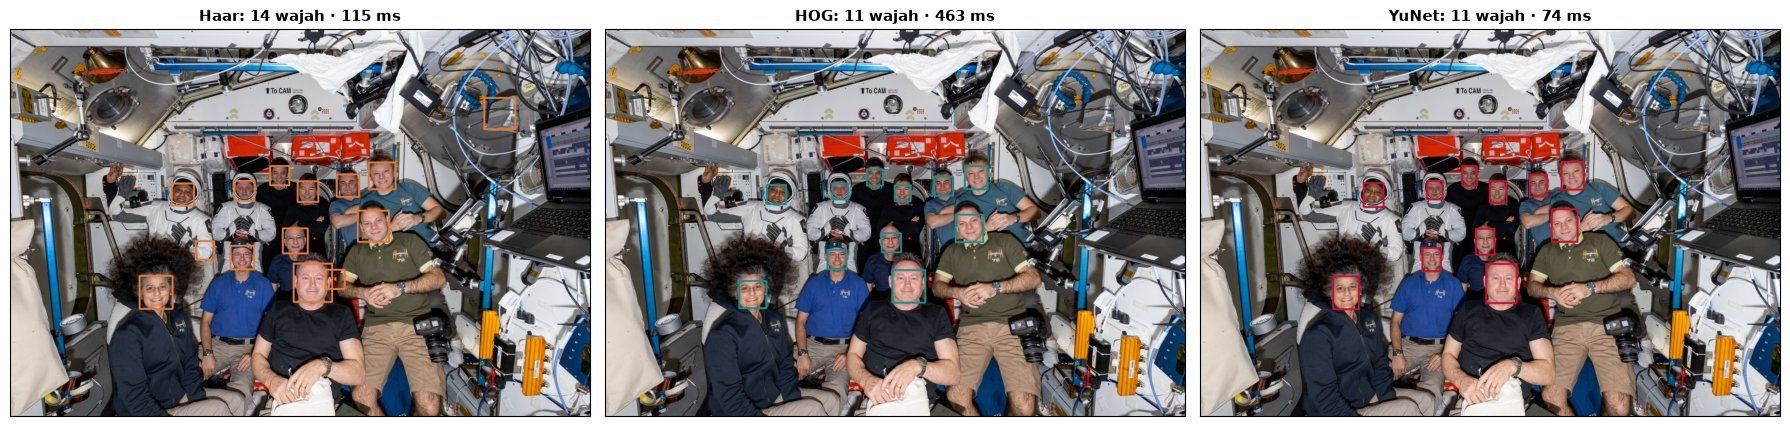

In [10]:
DETEKTOR = [("Haar", deteksi_haar, (57, 123, 224)), ("YuNet", deteksi_yunet, (46, 16, 200))]
if deteksi_hog is not None:
    DETEKTOR.insert(1, ("HOG", deteksi_hog, (140, 140, 30)))


def adu(img, judul_foto):
    fig, axs = plt.subplots(1, len(DETEKTOR), figsize=(6 * len(DETEKTOR), 4.4))
    for ax, (nama, fn, warna) in zip(axs, DETEKTOR):
        fn(img[:200, :200])                                    # pemanasan (sekali jalan pertama selalu lambat)
        t = time.perf_counter(); hasil = fn(img); dt = (time.perf_counter() - t) * 1000
        v = img.copy()
        for b in hasil:
            kotak(v, b, warna, 4)
        tampil(ax, v, f"{nama}: {len(hasil)} wajah · {dt:.0f} ms")
        print(f"{judul_foto:12s} {nama:6s}: {len(hasil):2d} wajah, {dt:6.0f} ms")
    plt.tight_layout(); plt.show()


adu(EXP72, "Ekspedisi72")

Di slide ada juga detektor **CNN milik dlib** (`mmod_human_face_detector`): sama telitinya dengan HOG di foto ini, tetapi
**±37 detik** per foto di CPU (tanpa GPU), sementara YuNet hanya **±50 ms**. Pelajarannya: *CNN tidak otomatis lambat —
tergantung seberapa besar jaringannya.*

### 2.4 Foto Kru STS-131: Wajah Terbalik!
Di luar angkasa tidak ada "atas" dan "bawah". Foto ini berisi **13 orang**, sebagian kepalanya di bawah.

STS-131      Haar  : 10 wajah,     93 ms


STS-131      HOG   :  6 wajah,    412 ms
STS-131      YuNet : 11 wajah,     64 ms


[ WARN:0@3.387] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now
[ WARN:0@3.391] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


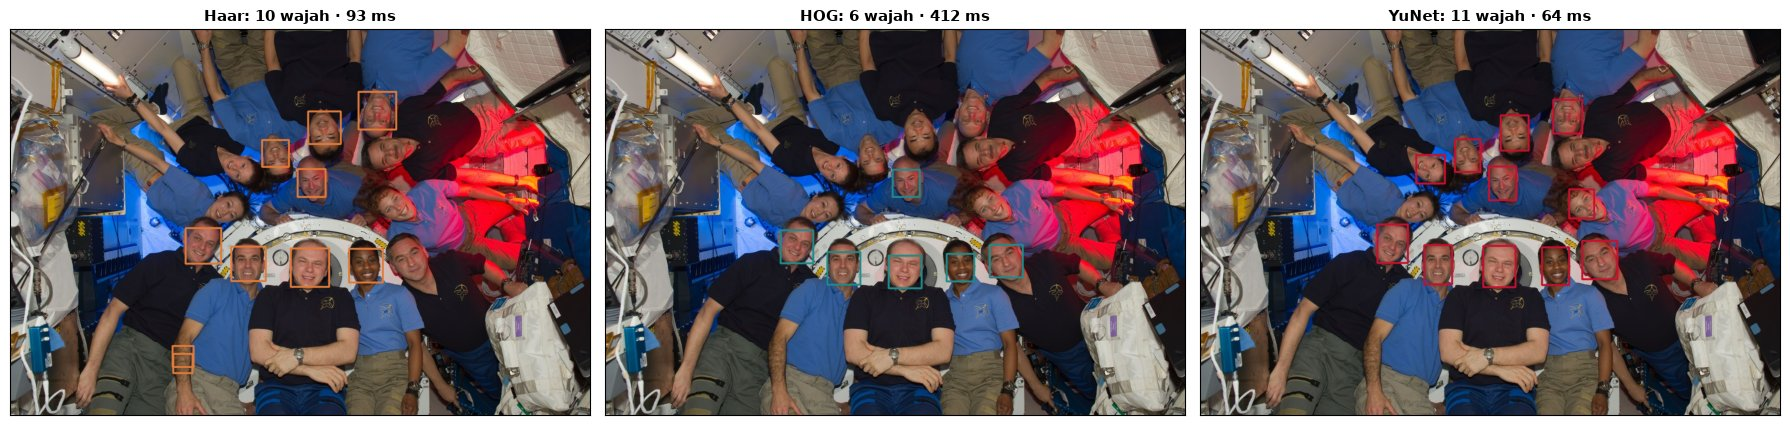

In [11]:
adu(STS, "STS-131")

### 2.5 Uji Ketahanan
Kita "siksa" foto astronaut: dimiringkan, digelapkan, diperkecil, dan diberi masker. Detektor mana yang tetap menemukan wajah?

                Haar     HOG   YuNet
Asli              ✅      ✅      ✅
Miring 20°        ✅      ✅      ✅


[ WARN:0@3.878] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now
[ WARN:0@3.968] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now
[ WARN:0@4.055] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


Miring 45°        ❌      ✅      ✅
Gelap             ✅      ✅      ✅
Kecil             ❌      ❌      ✅


[ WARN:0@4.144] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now
[ WARN:0@4.228] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now
[ WARN:0@4.322] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


Masker            ❌      ❌      ✅


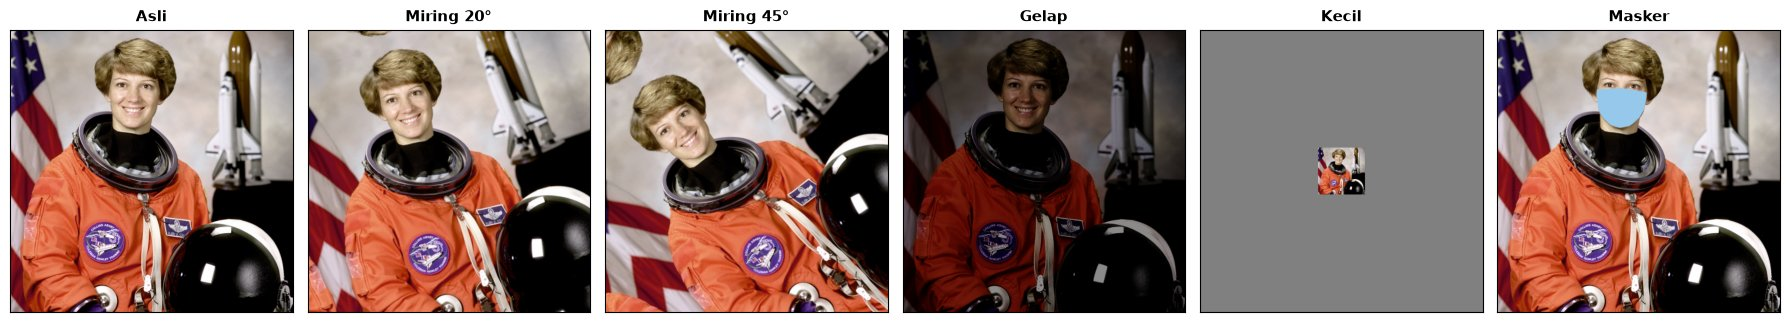

In [12]:
cx0, cy0 = x + w / 2, y + h / 2       # pusat wajah asli


def varian():
    hh, ww = ASTRO.shape[:2]
    yield "Asli", ASTRO.copy(), (cx0, cy0)
    for sudut in (20, 45):            # ✏️ Coba Ubah: tambahkan 30 atau 90
        M = cv2.getRotationMatrix2D((ww / 2, hh / 2), sudut, 1.0)
        yield f"Miring {sudut}°", cv2.warpAffine(ASTRO, M, (ww, hh), borderMode=cv2.BORDER_REFLECT), \
            tuple(M @ np.array([cx0, cy0, 1]))
    yield "Gelap", np.clip(((ASTRO / 255.0) ** 2.6) * 255 * 0.55, 0, 255).astype(np.uint8), (cx0, cy0)
    kecil = np.full((hh, ww, 3), 128, np.uint8)
    k = cv2.resize(ASTRO, (ww // 6, hh // 6), interpolation=cv2.INTER_AREA)
    kecil[hh // 2 - hh // 12:hh // 2 - hh // 12 + k.shape[0], ww // 2 - ww // 12:ww // 2 - ww // 12 + k.shape[1]] = k
    yield "Kecil", kecil, (ww // 2 - ww // 12 + cx0 / 6, hh // 2 - hh // 12 + cy0 / 6)
    masker = ASTRO.copy()
    hull = cv2.convexHull(TA[[234, 454, 152, 6, 93, 323, 58, 288, 172, 397, 136, 365, 150, 379, 149, 378, 176, 400]]
                          .astype(np.int32))
    cv2.fillConvexPoly(masker, hull, (235, 200, 150), cv2.LINE_AA)
    yield "Masker", masker, (cx0, cy0)


UJI = list(varian())
fig, axs = plt.subplots(1, len(UJI), figsize=(3 * len(UJI), 3.4))
print(f"{'':12s}" + "".join(f"{n:>8s}" for n, _, _ in DETEKTOR))
for ax, (nama, img, pusat) in zip(axs, UJI):
    baris = []
    for _, fn, _ in DETEKTOR:
        kena = any(b[0] <= pusat[0] <= b[0] + b[2] and b[1] <= pusat[1] <= b[1] + b[3] for b in fn(img))
        baris.append("✅" if kena else "❌")
    print(f"{nama:12s}" + "".join(f"{b:>7s}" for b in baris))
    tampil(ax, img, nama)
plt.tight_layout(); plt.show()

**Pelajaran:** Haar cepat tetapi rapuh (gagal saat miring, kecil, atau bermasker). CNN seperti YuNet paling tahan banting
karena **pernah melihat** wajah miring, kecil, dan tertutup saat dilatih.

---
## 3. Titik-Titik Wajah (Facial Landmarks)

Kotak saja tidak cukup untuk memasang kacamata: kita perlu tahu **di mana persisnya mata**. **Landmark** = titik-titik
penting di wajah dengan **nomor tetap** (titik nomor 1 selalu ujung hidung, di wajah siapa pun).

| Model | Jumlah titik | Catatan |
|---|---|---|
| **dlib 68** | 68 | Klasik: rahang 17, alis 10, hidung 9, mata 12, mulut 20. Model ±100 MB |
| **MediaPipe Face Mesh** | 468 (+10 iris = **478**) | Lebih rapat & 3D. Model ±3,7 MB, cukup cepat untuk HP |

Kita memakai **MediaPipe Face Landmarker** (sudah dibuat di Bagian 2.1 sebagai `LM_IMG`).

In [13]:
print(f"Jumlah wajah: {len(hasil_astro.face_landmarks)}")
print(f"Jumlah titik: {len(TA)}")
print("Bentuk array titik:", TA.shape, "→ setiap baris = (x, y) dalam piksel")
for i, nama in [(1, "ujung hidung"), (33, "sudut luar mata kanan"), (263, "sudut luar mata kiri"),
                (13, "bibir atas"), (152, "dagu")]:
    print(f"  titik {i:3d} ({nama:22s}): x={TA[i][0]:.0f}, y={TA[i][1]:.0f}")

Jumlah wajah: 1
Jumlah titik: 478
Bentuk array titik: (478, 2) → setiap baris = (x, y) dalam piksel
  titik   1 (ujung hidung          ): x=224, y=131
  titik  33 (sudut luar mata kanan ): x=195, y=101
  titik 263 (sudut luar mata kiri  ): x=255, y=104
  titik  13 (bibir atas            ): x=223, y=143
  titik 152 (dagu                  ): x=221, y=177


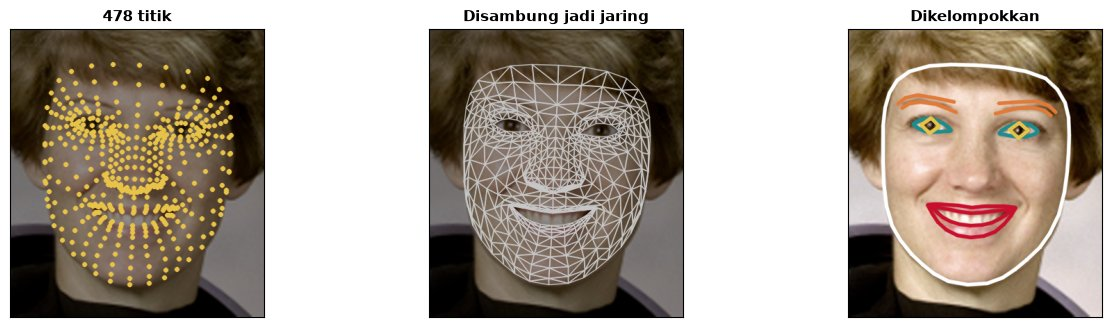

In [14]:
# Tampilkan titik, jaring (mesh), dan kelompok
K = vision.FaceLandmarksConnections
xa, ya = TA.min(0); xb, yb = TA.max(0); pad = 0.18 * (xb - xa)
r0, r1, c0, c1 = int(max(0, ya - pad)), int(yb + pad), int(max(0, xa - pad)), int(xb + pad)
S = 3                                                     # perbesar 3x agar titik terlihat
base = cv2.resize(ASTRO[r0:r1, c0:c1], None, fx=S, fy=S, interpolation=cv2.INTER_CUBIC)
T = (TA - [c0, r0]) * S


def garis(img, sambungan, warna, tebal=1):
    for s in sambungan:
        cv2.line(img, tuple(np.int32(T[s.start])), tuple(np.int32(T[s.end])), warna, tebal, cv2.LINE_AA)


img_titik = (base * 0.55).astype(np.uint8)
for p in T:
    cv2.circle(img_titik, tuple(np.int32(p)), 3, (74, 195, 232), -1, cv2.LINE_AA)
img_jaring = (base * 0.55).astype(np.uint8)
garis(img_jaring, K.FACE_LANDMARKS_TESSELATION, (200, 200, 200))
img_grup = base.copy()
garis(img_grup, K.FACE_LANDMARKS_FACE_OVAL, (255, 255, 255), 3)
garis(img_grup, K.FACE_LANDMARKS_LIPS, (46, 16, 200), 3)
garis(img_grup, K.FACE_LANDMARKS_LEFT_EYEBROW + K.FACE_LANDMARKS_RIGHT_EYEBROW, (57, 123, 224), 3)
garis(img_grup, K.FACE_LANDMARKS_LEFT_EYE + K.FACE_LANDMARKS_RIGHT_EYE, (140, 140, 30), 3)
garis(img_grup, K.FACE_LANDMARKS_LEFT_IRIS + K.FACE_LANDMARKS_RIGHT_IRIS, (74, 195, 232), 3)
jajar([(img_titik, f"{len(TA)} titik"), (img_jaring, "Disambung jadi jaring"), (img_grup, "Dikelompokkan")], 4.5)

### Bonus: Face Landmarker Juga Menebak Ekspresi
Opsi `output_face_blendshapes=True` memberi **52 skor ekspresi** (0 = tidak ada, 1 = sangat jelas), misalnya `mouthSmileLeft`,
`eyeBlinkRight`, `jawOpen`. Skor inilah yang dipakai aplikasi **avatar/animoji** untuk menggerakkan karakter kartun.

In [15]:
skor = sorted(((c.category_name, c.score) for c in hasil_astro.face_blendshapes[0]), key=lambda t: -t[1])
skor = [s for s in skor if s[0] != "_neutral"][:6]
for nama, nilai in skor:
    print(f"{nama:18s} {nilai:.2f}  " + "█" * int(nilai * 30))

mouthSmileRight    0.90  ███████████████████████████
mouthSmileLeft     0.90  ██████████████████████████
mouthUpperUpRight  0.47  ██████████████
mouthUpperUpLeft   0.47  ██████████████
eyeSquintLeft      0.35  ██████████
eyeSquintRight     0.27  ████████


---
## 4. Mata Terbuka atau Tertutup? (Eye Aspect Ratio)

Dari 6 titik di sekitar satu mata (p1 & p4 = sudut mata, p2 & p3 = kelopak atas, p6 & p5 = kelopak bawah):

$$\text{EAR} = \frac{\text{tinggi mata}}{\text{lebar mata}} = \frac{\tfrac{1}{2}\,(|p_2-p_6| + |p_3-p_5|)}{|p_1-p_4|}$$

Dalam bahasa sehari-hari: **seberapa "gepeng" mata**. Mata terbuka ±0,3; mata tertutup mendekati 0.
Rumus ini diperkenalkan oleh Soukupová & Čech (2016).

In [16]:
def ear(titik, idx):
    p1, p2, p3, p4, p5, p6 = [titik[i] for i in idx]
    tinggi = (np.linalg.norm(p2 - p6) + np.linalg.norm(p3 - p5)) / 2
    lebar = np.linalg.norm(p1 - p4)
    return tinggi / lebar


print(f"EAR astronaut: mata kanan {ear(TA, MATA_KANAN):.3f}, mata kiri {ear(TA, MATA_KIRI):.3f}")

EAR astronaut: mata kanan 0.312, mata kiri 0.312


### 🎬 Demo Dosen — EAR Sepanjang Video Wawancara
Video 20 detik (24 fps). Untuk video kita pakai mode **`VIDEO`**: MediaPipe memakai hasil frame sebelumnya sehingga lebih
cepat dan stabil, tetapi butuh **waktu (milidetik)** setiap frame.

**Tebak dulu:** berapa kali Dr. Young berkedip dalam 20 detik? (Orang dewasa rata-rata berkedip 15–20 kali per menit.)

In [17]:
cap = cv2.VideoCapture(cari_file("video/wawancara_kedip.mp4"))
FPS = cap.get(cv2.CAP_PROP_FPS)
VID = []
while True:
    ok, f = cap.read()
    if not ok:
        break
    VID.append(f)
cap.release()
print(f"{len(VID)} frame, {FPS:.3f} fps, {len(VID) / FPS:.1f} detik, ukuran {VID[0].shape}")

LM_VID = buat_landmarker("VIDEO")
t = time.perf_counter()
EAR, BLINK, TITIK = [], [], []
for i, f in enumerate(VID):
    r = LM_VID.detect_for_video(ke_mp(f), int(i * 1000 / FPS))   # waktu frame dalam milidetik
    if r.face_landmarks:
        tt = titik_wajah(r, f.shape[1], f.shape[0])
        EAR.append((ear(tt, MATA_KANAN) + ear(tt, MATA_KIRI)) / 2)   # rata-rata dua mata
        s = {c.category_name: c.score for c in r.face_blendshapes[0]}
        BLINK.append((s["eyeBlinkLeft"] + s["eyeBlinkRight"]) / 2)
        TITIK.append(tt)
    else:
        EAR.append(np.nan); BLINK.append(np.nan); TITIK.append(None)
EAR, BLINK = np.array(EAR), np.array(BLINK)
dt = time.perf_counter() - t
print(f"Selesai dalam {dt:.1f} detik ({len(VID) / dt:.0f} frame per detik)")
print(f"EAR median {np.nanmedian(EAR):.3f}, terkecil {np.nanmin(EAR):.3f}, terbesar {np.nanmax(EAR):.3f}")

479 frame, 23.976 fps, 20.0 detik, ukuran (360, 640, 3)


W0000 00:00:1794466307.139480 3974053 face_landmarker_graph.cc:181] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1794466307.144147 3974056 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794466307.154332 3974057 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Selesai dalam 3.1 detik (154 frame per detik)
EAR median 0.346, terkecil 0.010, terbesar 0.384


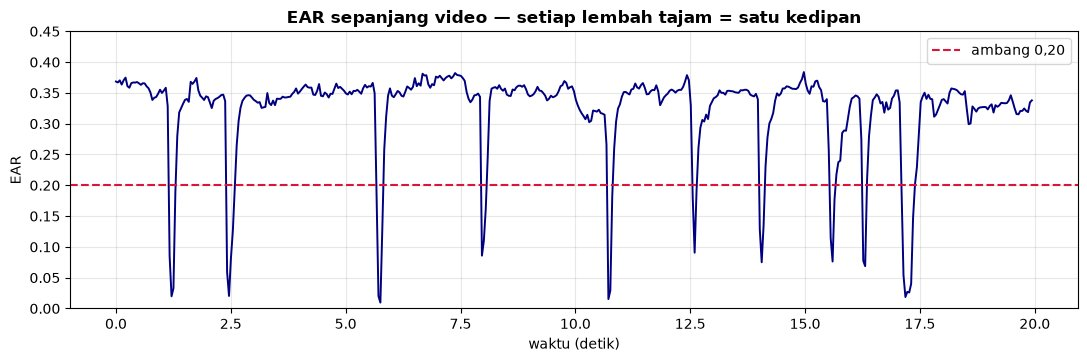

In [18]:
tsec = np.arange(len(EAR)) / FPS
plt.figure(figsize=(13, 3.6))
plt.plot(tsec, EAR, color="navy", lw=1.4)
plt.axhline(0.20, color="crimson", ls="--", label="ambang 0,20")
plt.xlabel("waktu (detik)"); plt.ylabel("EAR"); plt.ylim(0, 0.45); plt.legend(); plt.grid(alpha=0.3)
plt.title("EAR sepanjang video — setiap lembah tajam = satu kedipan", fontweight="bold")
plt.show()

### Menghitung Kedip
Aturannya sederhana: **EAR turun di bawah ambang selama minimal beberapa frame, lalu naik lagi = 1 kedip.**
Syarat "minimal beberapa frame" mencegah satu frame yang kebetulan bergoyang ikut dihitung.

In [19]:
def hitung_kedip(nilai_ear, ambang=0.20, min_frame=2):
    jumlah, berturut, awal = 0, 0, []
    for i, e in enumerate(list(nilai_ear) + [1.0]):      # tambah 1.0 di akhir agar kedip terakhir ikut ditutup
        if e < ambang:
            berturut += 1
        else:
            if berturut >= min_frame:
                jumlah += 1
                awal.append(i - berturut)
            berturut = 0
    return jumlah, awal


n_kedip, awal = hitung_kedip(EAR, 0.20, 2)
print(f"Kedip: {n_kedip} kali dalam {len(VID) / FPS:.0f} detik = {n_kedip / (len(VID) / FPS) * 60:.0f} kali per menit")
print("Dimulai di frame:", awal)

Kedip: 10 kali dalam 20 detik = 30 kali per menit
Dimulai di frame: [28, 58, 136, 191, 257, 301, 336, 373, 390, 410]


In [20]:
# ✏️ Coba Ubah: ambang dan min_frame. Kapan hasilnya mulai kacau?
print("ambang | min 1 frame | min 2 frame | min 3 frame")
for ambang in [0.12, 0.15, 0.20, 0.25, 0.30]:
    print(f" {ambang:.2f}  |" + "|".join(f"{hitung_kedip(EAR, ambang, mf)[0]:^13d}" for mf in (1, 2, 3)))
print(f"\nPembanding — skor blendshape eyeBlink > 0,5: {hitung_kedip(1 - BLINK, 0.5, 2)[0]} kedip")

ambang | min 1 frame | min 2 frame | min 3 frame
 0.12  |     10      |      8      |      3      
 0.15  |     10      |      9      |      5      
 0.20  |     10      |     10      |      9      
 0.25  |     10      |     10      |     10      
 0.30  |     11      |     10      |     10      

Pembanding — skor blendshape eyeBlink > 0,5: 8 kedip


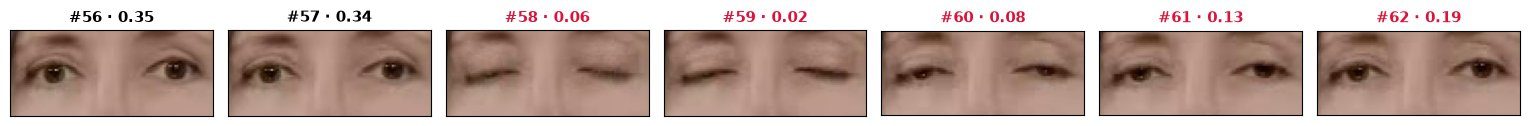

Lama tiap kedip (frame): [4, 5, 4, 3, 3, 3, 3, 3, 2, 7] → rata-rata 154 ms


In [21]:
# Lihat satu kedipan frame demi frame
a = awal[1]
idx = list(range(a - 2, a + 5))
fig, axs = plt.subplots(1, len(idx), figsize=(2.2 * len(idx), 1.9))
for ax, i in zip(axs, idx):
    p = np.vstack([TITIK[i][MATA_KANAN], TITIK[i][MATA_KIRI]])
    cx_, cy_ = p.mean(0); lw = (p[:, 0].max() - p[:, 0].min()) * 0.62
    tampil(ax, VID[i][int(cy_ - lw * 0.42):int(cy_ + lw * 0.42), int(cx_ - lw):int(cx_ + lw)], f"#{i} · {EAR[i]:.2f}")
    if EAR[i] < 0.2:
        ax.title.set_color("crimson")
plt.tight_layout(); plt.show()

dur = []
for a in awal:
    k = a
    while k < len(EAR) and EAR[k] < 0.20:
        k += 1
    dur.append(k - a)
print(f"Lama tiap kedip (frame): {dur} → rata-rata {np.mean(dur) / FPS * 1000:.0f} ms")

### Dari Kedip ke "Mengantuk"
Kedip normal hanya **±150 ms** (3–4 frame). Kalau mata tertutup **lebih dari ±1 detik**, besar kemungkinan orangnya
**mengantuk** — inilah ide sistem peringatan kantuk pengemudi (*driver drowsiness detection*). Logikanya cukup satu baris:
`if berturut > FPS * 1.0: peringatan()`. Script `11_filter_wajah.py` di Bagian 9 sudah memakainya.

---
## 5. Kode Hitam-Putih: Barcode & QR Code

### 5.1 Barcode EAN-13
Barcode di kemasan produk berisi **13 angka**. Tiga angka pertama menunjukkan **negara pendaftar** — **899 = Indonesia**.
Angka terakhir adalah **angka cek** untuk memeriksa salah baca.

In [22]:
def digit_cek(dua_belas):
    d = [int(c) for c in dua_belas]
    ganjil, genap = sum(d[0::2]), sum(d[1::2])       # posisi ke-1,3,5,... dan ke-2,4,6,...
    return (10 - (ganjil + 3 * genap) % 10) % 10


print("Angka cek untuk 899123411111 →", digit_cek("899123411111"))
print("Angka cek untuk 899123411112 →", digit_cek("899123411112"), "(satu angka berbeda, cek ikut berubah)")

Angka cek untuk 899123411111 → 7
Angka cek untuk 899123411112 → 4 (satu angka berbeda, cek ikut berubah)


Terbaca: True | isi: ('8991234111117',) | jenis: ('EAN_13',)


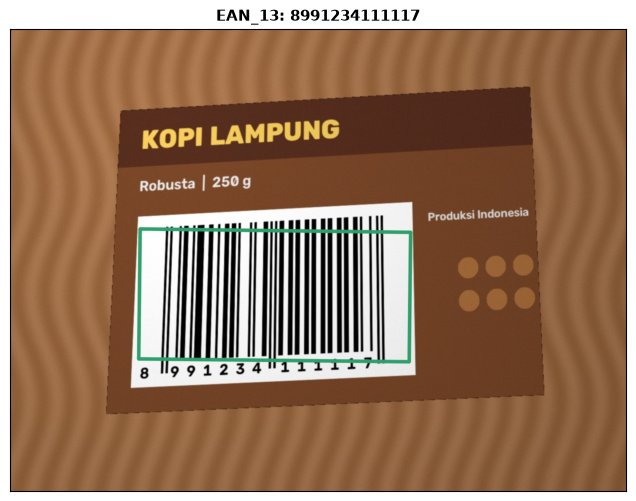

Digit cek benar? True


In [23]:
BARC = cv2.imread(cari_file("image/barcode_produk.jpg"))
bd = cv2.barcode.BarcodeDetector()
hasil = bd.detectAndDecodeWithType(BARC)
# OpenCV 4.x & 5.x: (ok, isi, jenis, titik_sudut)
ok, isi, jenis, sudut = hasil if len(hasil) == 4 else (True, *hasil)
print("Terbaca:", ok, "| isi:", isi, "| jenis:", jenis)
v = BARC.copy()
if sudut is not None:
    for q in sudut:
        cv2.polylines(v, [q.astype(np.int32)], True, (107, 158, 46), 6, cv2.LINE_AA)
plt.figure(figsize=(8, 6)); tampil(plt.gca(), v, f"{jenis[0]}: {isi[0]}"); plt.show()
print("Digit cek benar?", digit_cek(isi[0][:12]) == int(isi[0][12]))

### 5.2 QR Code: Anatomi
QR code adalah barcode **dua dimensi**. Bagian pentingnya:
- **3 kotak penanda (finder)** di tiga sudut → kamera tahu *ini QR* dan *arah atasnya* (kenapa 3, bukan 4? supaya arahnya tidak ambigu);
- **garis putus-putus (timing)** → penggaris untuk menghitung jumlah kotak kecil (modul);
- **kotak bantu (alignment)** → membantu saat kertas melengkung;
- **data + cadangan** → isi pesan ditambah salinan cadangan (*error correction*) agar tetap terbaca walau rusak.

Membuat QR cukup dengan `cv2.QRCodeEncoder`:

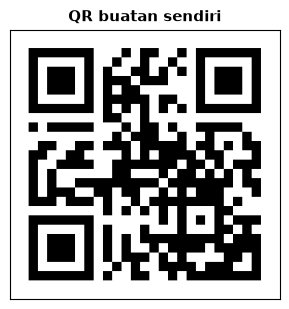

Ukuran gambar: (290, 290) → disimpan di output/qr_saya.png, coba scan dengan HP!


In [24]:
def buat_qr(teks, level=cv2.QRCODE_ENCODER_CORRECT_LEVEL_M, modul=10):
    p = cv2.QRCodeEncoder.Params()
    p.correction_level = level
    q = cv2.QRCodeEncoder.create(p).encode(teks)          # 1 piksel = 1 modul
    return cv2.resize(q, None, fx=modul, fy=modul, interpolation=cv2.INTER_NEAREST)


# ✏️ Coba Ubah: isi teks QR
qr = buat_qr("https://mctm.web.id/stm")
cv2.imwrite("output/qr_saya.png", qr)
plt.figure(figsize=(3.5, 3.5)); tampil(plt.gca(), qr, "QR buatan sendiri"); plt.show()
print("Ukuran gambar:", qr.shape, "→ disimpan di output/qr_saya.png, coba scan dengan HP!")

### 🎬 Demo Dosen — Membaca QR di Kertas Miring
Langkahnya: **(1)** cari 3 kotak penanda, **(2)** tentukan 4 sudut QR, **(3)** luruskan dengan transformasi perspektif
(Pertemuan 7!), **(4)** baca modul hitam-putihnya.

Isi QR : https://mctm.web.id/stm
4 sudut: [[373.0, 235.0], [642.0, 273.0], [614.0, 499.0], [331.0, 453.0]]


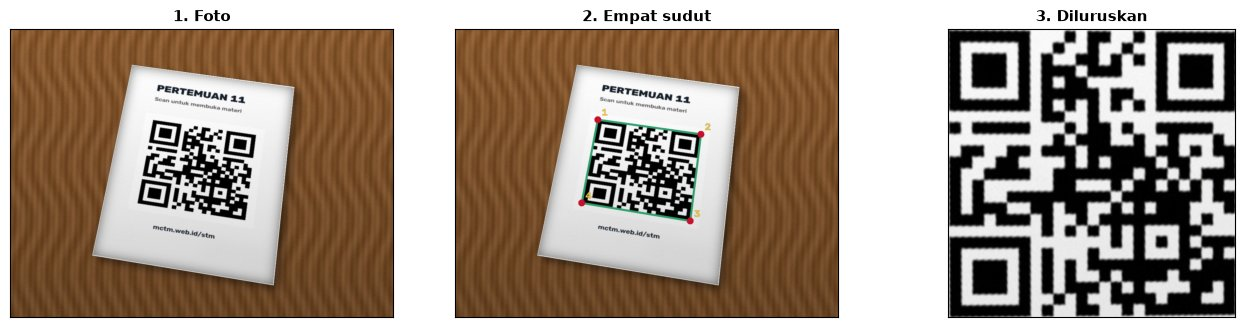

In [25]:
QRMEJA = cv2.imread(cari_file("image/qr_meja.jpg"))
QRD = cv2.QRCodeDetector()
teks, titik, lurus = QRD.detectAndDecode(QRMEJA)
print("Isi QR :", teks)
qp = titik.reshape(-1, 2)
print("4 sudut:", qp.round(0).tolist())

v = QRMEJA.copy()
cv2.polylines(v, [qp.astype(np.int32)], True, (107, 158, 46), 4, cv2.LINE_AA)
for k, p in enumerate(qp):
    cv2.circle(v, tuple(np.int32(p)), 9, (46, 16, 200), -1)
    tulis(v, str(k + 1), (int(p[0]) + 10, int(p[1]) - 10), 0.9, (74, 195, 232))
UK = 360
M = cv2.getPerspectiveTransform(qp.astype(np.float32), np.float32([[0, 0], [UK, 0], [UK, UK], [0, UK]]))
jajar([(QRMEJA, "1. Foto"), (v, "2. Empat sudut"), (cv2.warpPerspective(QRMEJA, M, (UK, UK)), "3. Diluruskan")], 4.5)

### 5.3 QR Tahan Rusak (Error Correction)
QR punya 4 **level koreksi**: **L** (±7%), **M** (±15%), **Q** (±25%), **H** (±30%) — kira-kira berapa persen data yang boleh hilang.
Makin tinggi levelnya, makin banyak cadangan, sehingga QR jadi lebih besar/rapat. Kita uji dengan menutup **bagian tengah** QR
memakai stiker yang makin lama makin besar.

In [26]:
LEVEL = [("L", cv2.QRCODE_ENCODER_CORRECT_LEVEL_L), ("M", cv2.QRCODE_ENCODER_CORRECT_LEVEL_M),
         ("Q", cv2.QRCODE_ENCODER_CORRECT_LEVEL_Q), ("H", cv2.QRCODE_ENCODER_CORRECT_LEVEL_H)]
TEKS = "https://mctm.web.id/stm"


def tutup_tengah(qr, persen, isi=None):
    # tempel "stiker" persegi di tengah QR, luasnya = persen dari luas QR
    q = cv2.cvtColor(qr, cv2.COLOR_GRAY2BGR)
    hit = np.where(qr < 128)
    a0, a1 = hit[0].min(), hit[0].max()
    sisi = int(np.sqrt(persen / 100) * (a1 - a0))
    c = (a0 + a1) // 2
    if sisi > 0:
        tambal = (60, 160, 230) if isi is None else cv2.resize(isi, (sisi, sisi))
        q[c - sisi // 2:c - sisi // 2 + sisi, c - sisi // 2:c - sisi // 2 + sisi] = tambal
    return q


def terbaca(img):
    try:
        t, *_ = QRD.detectAndDecode(img)
    except cv2.error:                                     # 4 sudut berimpit -> anggap gagal
        return False
    return t == TEKS


for nama, lv in LEVEL:
    qr = buat_qr(TEKS, lv, modul=8)
    maks = 0
    while terbaca(tutup_tengah(qr, maks + 1)):            # tambah 1% sampai gagal
        maks += 1
    print(f"Level {nama}: masih terbaca sampai bagian tengah tertutup {maks}%")

Level L: masih terbaca sampai bagian tengah tertutup 5%


Level M: masih terbaca sampai bagian tengah tertutup 9%
Level Q: masih terbaca sampai bagian tengah tertutup 12%


Level H: masih terbaca sampai bagian tengah tertutup 17%


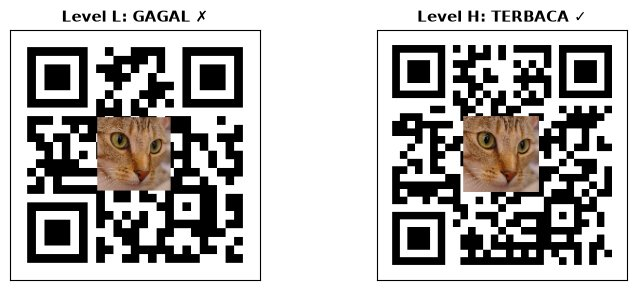

In [27]:
# QR dengan logo di tengah (seperti QR di kemasan). ✏️ Coba Ubah: persen logo
KUCING = cv2.imread(cari_file("image/chelsea.png"))
logo = KUCING[30:330, 80:380]
PERSEN = 12
daftar = []
for nama, lv in [LEVEL[0], LEVEL[3]]:
    q = tutup_tengah(buat_qr(TEKS, lv, modul=8), PERSEN, logo)
    daftar.append((q, f"Level {nama}: {'TERBACA ✓' if terbaca(q) else 'GAGAL ✗'}"))
jajar(daftar, 4)

> 💡 Angka uji kita lebih kecil dari angka teori karena stiker di tengah menghancurkan data **dan** sebagian pola bantu,
> dan detektor OpenCV lebih "rewel" daripada aplikasi kamera HP. Polanya tetap sama: **H paling tahan**, L paling rapuh.

---
## 6. Tempel Gambar: AR Sederhana

### 6.1 Kanal Alpha
Gambar PNG bisa punya kanal ke-4, **alpha** (0 = tembus pandang, 255 = penuh). Menempel gambar = mencampur dua gambar per piksel:

`hasil = gambar × alpha + latar × (1 − alpha)`

Ini sama dengan *blending* di Pertemuan 6, hanya saja bobotnya berbeda di setiap piksel.

Ukuran kacamata.png: (240, 600, 4) → 4 kanal: B, G, R, alpha


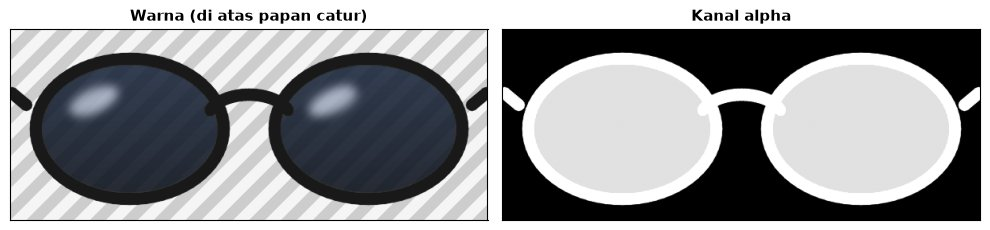

In [28]:
KACAMATA = cv2.imread(cari_file("image/kacamata.png"), cv2.IMREAD_UNCHANGED)   # UNCHANGED = alpha ikut dibaca
print("Ukuran kacamata.png:", KACAMATA.shape, "→ 4 kanal: B, G, R, alpha")
JANGKAR = np.float32([[150, 125], [450, 125]])     # pusat lensa kiri & kanan di kacamata.png


def tempel_rgba(latar, gambar_rgba, M):
    # Tempel gambar RGBA ke latar memakai matriks M (2x3 affine atau 3x3 perspektif)
    h, w = latar.shape[:2]
    if M.shape == (2, 3):
        warp = cv2.warpAffine(gambar_rgba, M, (w, h), flags=cv2.INTER_LINEAR, borderValue=(0, 0, 0, 0))
    else:
        warp = cv2.warpPerspective(gambar_rgba, M, (w, h), flags=cv2.INTER_LINEAR, borderValue=(0, 0, 0, 0))
    alpha = warp[..., 3:4].astype(np.float32) / 255.0
    return (warp[..., :3] * alpha + latar * (1 - alpha)).astype(np.uint8)


papan = np.where((np.indices(KACAMATA.shape[:2]).sum(0) // 20 % 2)[..., None] == 1, 205, 245).astype(np.uint8).repeat(3, 2)
al = KACAMATA[..., 3:4] / 255.0
jajar([((KACAMATA[..., :3] * al + papan * (1 - al)).astype(np.uint8), "Warna (di atas papan catur)"),
       (KACAMATA[..., 3], "Kanal alpha")], 5)

### 6.2 Kacamata yang Mengikuti Mata
Supaya dua lensa jatuh tepat di dua mata, kacamata harus **digeser, diputar, dan diperbesar** — tiga transformasi Pertemuan 7.
Dari dua pasang titik (pusat lensa ↔ pusat mata), `cv2.estimateAffinePartial2D` langsung menghitung matriksnya.

Jarak dua mata: 43 px → kacamata diperkecil 0.14x | sudut garis mata: 3.1°


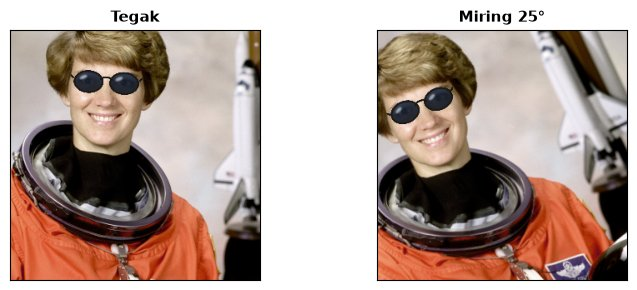

In [29]:
def pasang_kacamata(img, titik, lebar=1.0):
    a, b = pusat_mata(titik)
    tengah = (a + b) / 2
    a2, b2 = tengah + (a - tengah) * lebar, tengah + (b - tengah) * lebar
    M, _ = cv2.estimateAffinePartial2D(JANGKAR, np.float32([a2, b2]))
    return tempel_rgba(img, KACAMATA, M)


a, b = pusat_mata(TA)
jarak = np.linalg.norm(b - a)
sudut = np.degrees(np.arctan2(b[1] - a[1], b[0] - a[0]))
print(f"Jarak dua mata: {jarak:.0f} px → kacamata diperkecil {jarak / 300:.2f}x | sudut garis mata: {sudut:.1f}°")

# kepala dimiringkan 25 derajat -> kacamata ikut miring
hh, ww = ASTRO.shape[:2]
miring = cv2.warpAffine(ASTRO, cv2.getRotationMatrix2D((ww / 2, hh / 2), 25, 1.0), (ww, hh), borderMode=cv2.BORDER_REFLECT)
tm = titik_wajah(LM_IMG.detect(ke_mp(miring)), ww, hh)
# ✏️ Coba Ubah: lebar=1.2 membuat kacamata lebih lebar
jajar([(pasang_kacamata(ASTRO, TA)[40:340, 110:410], "Tegak"),
       (pasang_kacamata(miring, tm)[40:340, 110:410], "Miring 25°")], 4)

### 6.3 Gambar di Atas QR (Marker AR)
QR yang terdeteksi memberi **4 sudut**. Empat titik cukup untuk transformasi **perspektif** (homografi), sehingga gambar apa pun
bisa "ditempel" seolah-olah tercetak di kertas itu. Inilah prinsip **marker-based AR**: kode di dunia nyata menjadi panggung
untuk konten digital.

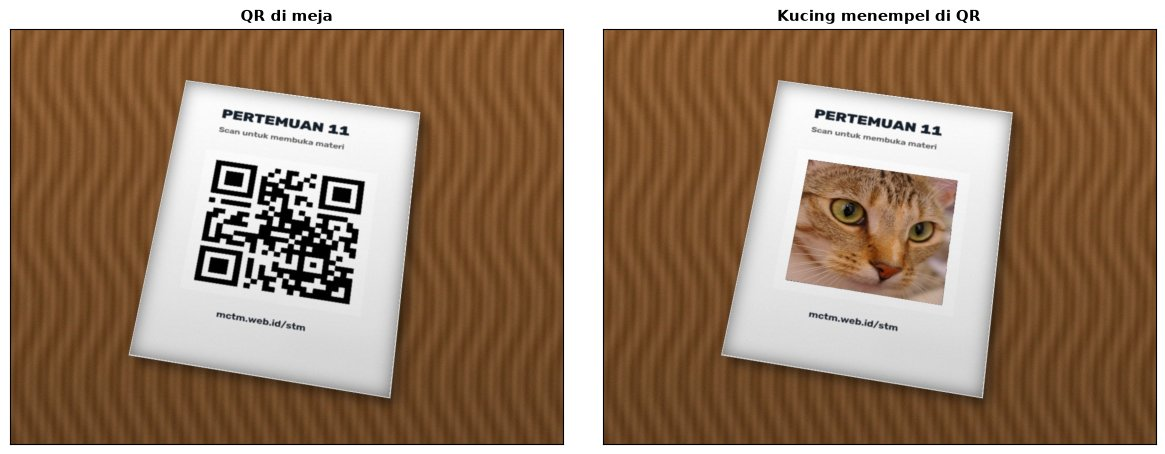

In [30]:
hk, wk = KUCING.shape[:2]
sisi = min(hk, wk)
kucing_persegi = cv2.cvtColor(KUCING[(hk - sisi) // 2:(hk + sisi) // 2, (wk - sisi) // 2:(wk + sisi) // 2], cv2.COLOR_BGR2BGRA)
M = cv2.getPerspectiveTransform(np.float32([[0, 0], [sisi, 0], [sisi, sisi], [0, sisi]]), qp.astype(np.float32))
jajar([(QRMEJA, "QR di meja"), (tempel_rgba(QRMEJA, kucing_persegi, M), "Kucing menempel di QR")], 6)

---
## 7. Studi Kasus: Kacamata + Penghitung Kedip di Video

Gabungkan Bagian 3, 4, dan 6 untuk setiap frame video wawancara: cari titik wajah → hitung EAR → perbarui penghitung → tempel kacamata.

Penghitung akhir: 10


MP4 disimpan: output/kacamata_kedip.mp4


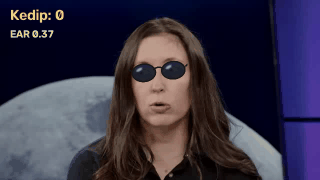

GIF disimpan: output/kacamata_kedip.gif (1760 KB)


In [31]:
hasil_video, hit, berturut = [], 0, 0
for i, f in enumerate(VID):
    g = f.copy()
    if TITIK[i] is not None:
        e = EAR[i]
        if e < 0.20:
            berturut += 1
        else:
            if berturut >= 2:
                hit += 1
            berturut = 0
        g = pasang_kacamata(g, TITIK[i])
        tulis(g, f"Kedip: {hit}", (20, 40), 1.0, (74, 195, 232))
        tulis(g, f"EAR {e:.2f}", (20, 75), 0.7)
    hasil_video.append(g)
print("Penghitung akhir:", hit)

# simpan MP4 (bisa diputar di laptop) + tampilkan GIF di notebook
tulis_vid = cv2.VideoWriter("output/kacamata_kedip.mp4", cv2.VideoWriter_fourcc(*"mp4v"), FPS, (640, 360))
for g in hasil_video:
    tulis_vid.write(g)
tulis_vid.release()
print("MP4 disimpan: output/kacamata_kedip.mp4")
tampil_gif(hasil_video[:192], "kacamata_kedip.gif", fps=FPS, lebar=320, langkah=3)

---
## 8. Etika: Deteksi ≠ Pengenalan

- **Deteksi** (hari ini): *ada wajah di sini.* Tidak tahu siapa orangnya.
- **Pengenalan** (*recognition*): *ini wajah si A.* Memerlukan database wajah — data pribadi yang sensitif.
- Di Indonesia, data biometrik termasuk **data pribadi spesifik** menurut **UU No. 27/2022 tentang Pelindungan Data Pribadi**.
  Merekam dan memproses wajah orang lain perlu **izin** dan **tujuan yang jelas**.
- Foto & video di modul ini adalah dokumentasi resmi NASA berstatus **domain publik**, sengaja dipilih agar aman dipakai belajar.

> Saat mencoba script webcam, pakailah wajah Anda sendiri (atau teman yang sudah setuju).

---
## 9. Finale: Filter Wajah Buatan Sendiri 🕶️

Script **`11_filter_wajah.py`** (di folder yang sama dengan notebook ini) menggabungkan semuanya secara **live**:

| Langkah tiap frame | Materi |
|---|---|
| `cv2.VideoCapture(0)` membaca webcam | Pertemuan 10 |
| MediaPipe mencari **478 titik wajah** (mode `VIDEO`) | Bagian 3 |
| **EAR** < 0,20 selama ≥ 2 frame lalu naik = 1 kedip; tertutup > 1 detik = "MENGANTUK?" | Bagian 4 |
| **Kacamata** digeser-putar-perbesar ke dua mata | Bagian 6.2 |
| Kalau ada **QR** di depan kamera: kucing ditempel di atasnya | Bagian 5.2 + 6.3 |

### Cara menjalankan (di laptop sendiri, bukan Colab)
```bash
cd notebook_handson
python 11_filter_wajah.py                    # pakai webcam
python 11_filter_wajah.py video.mp4          # atau file video berisi wajah
```
Tombol: **q** keluar · **k** kacamata on/off · **m** tampilkan 478 titik · **r** nolkan penghitung kedip.

Untuk mencoba AR: buka `output/qr_saya.png` di HP, lalu arahkan layar HP ke webcam.

### ✏️ Coba ubah di script
- `AMBANG_EAR = 0.20` → sesuaikan dengan mata Anda (lihat angka EAR di layar saat mata terbuka).
- Ganti `image/kacamata.png` dengan PNG transparan lain (topi, kumis — ubah juga `JANGKAR`).
- Tantangan: tempel **kumis** di antara hidung (titik 1) dan bibir atas (titik 13)!

Sel di bawah hanya menampilkan isi script agar mudah dibaca.

In [32]:
with open(cari_file("11_filter_wajah.py"), encoding="utf-8") as fh:
    print(fh.read())

"""
11_filter_wajah.py — Filter wajah buatan sendiri: kacamata hitam + penghitung kedip + QR jadi panggung AR
IF25-40305 Sistem Teknologi Multimedia · Modul 11 · ITERA

Cara menjalankan (di laptop sendiri, BUKAN di Colab, karena butuh webcam & jendela):
    python 11_filter_wajah.py                      # pakai webcam
    python 11_filter_wajah.py video.mp4            # atau pakai file video
    python 11_filter_wajah.py video.mp4 --simpan hasil.mp4   # tanpa jendela, hasil disimpan ke file

Tombol:  q = keluar   k = kacamata on/off   m = titik wajah on/off   r = nolkan penghitung kedip

Cara kerjanya (setiap frame):
  1. MediaPipe Face Landmarker mencari 478 titik wajah.
  2. Dari 6 titik di tiap mata dihitung EAR (tinggi mata / lebar mata).
     EAR < 0,20 selama >= 2 frame lalu naik lagi  -> dihitung 1 kedip.
     Mata tertutup > 1 detik                       -> muncul peringatan "MENGANTUK?".
  3. Kacamata (gambar PNG tembus pandang) diputar & diperbesar mengikuti dua mata, lalu di

---
## 10. Rangkuman

1. **Deteksi wajah** = mencari kotak wajah. Haar (pola terang-gelap) cepat tapi rapuh; HOG (arah tepi) lebih tahan cahaya;
   CNN (YuNet) paling tahan banting dan — kalau jaringannya kecil — juga paling cepat.
2. **Landmark** = titik wajah bernomor tetap. MediaPipe memberi **478 titik** + 52 skor ekspresi.
3. **EAR** = tinggi mata ÷ lebar mata. Turun di bawah ±0,2 beberapa frame = **kedip**; tertutup lama = **mengantuk**.
4. **Barcode EAN-13**: 13 angka, 899 = Indonesia, angka terakhir = cek. **QR**: 3 kotak penanda + data + cadangan (L/M/Q/H).
5. **AR sederhana** = alpha blending + transformasi: affine (2 titik mata) untuk kacamata, perspektif (4 sudut QR) untuk marker.
6. **Etika**: deteksi ≠ pengenalan; wajah adalah data pribadi.

### 🧭 Lembar Contekan
| Tujuan | Kode |
|---|---|
| Haar | `cv2.CascadeClassifier("model/haarcascade_frontalface_default.xml").detectMultiScale(abu, 1.1, 5)` |
| YuNet | `d = cv2.FaceDetectorYN.create("model/face_detection_yunet_2023mar.onnx", "", (w, h)); _, wajah = d.detect(img)` |
| HOG (dlib) | `dlib.get_frontal_face_detector()(rgb, 1)` |
| Landmark | `vision.FaceLandmarker.create_from_options(opsi).detect(mp.Image(...))` |
| Titik → piksel | `[[p.x * w, p.y * h] for p in hasil.face_landmarks[0]]` |
| EAR | `(jarak(p2, p6) + jarak(p3, p5)) / 2 / jarak(p1, p4)` |
| Baca QR | `teks, sudut, _ = cv2.QRCodeDetector().detectAndDecode(img)` |
| Buat QR | `cv2.QRCodeEncoder.create().encode("teks")` |
| Baca barcode | `cv2.barcode.BarcodeDetector().detectAndDecodeWithType(img)` |
| Baca PNG + alpha | `cv2.imread("x.png", cv2.IMREAD_UNCHANGED)` |
| Tempel 2 titik | `M, _ = cv2.estimateAffinePartial2D(titik_src, titik_dst); cv2.warpAffine(...)` |
| Tempel 4 titik | `M = cv2.getPerspectiveTransform(src4, dst4); cv2.warpPerspective(...)` |

> 🔜 **Pertemuan berikutnya:** Pose estimation (33 titik tubuh), hand tracking (21 titik tangan) & gesture recognition.